## 0. Installation and secure setup

Run the next code cell. Colab will display a hidden input box below it; paste
one Google AI Studio key there and press Enter.


# Task 3 - Simulating Human Knowledge Gaps
**LLMs, Theory of Mind, and OpenBookQA**

This notebook follows Sections 1-6 of Task 3. It keeps the structure of the
provided sample solution, but improves security, reproducibility, parsing,
checkpointing, and runtime.



The notebook refuses to continue when an API failure would make a required CSV
incomplete. Re-running a failed cell reuses cached successful calls.


In [1]:
%pip install -q -U datasets langchain-google-genai langchain-core json-repair


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.8/72.8 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.6/561.6 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 17.0 MB/s eta 0:00:00


In [2]:
from getpass import getpass

API_KEYS = [getpass("Paste your Google AI Studio API key: ").strip()]


Paste your Google AI Studio API key: ··········


In [3]:
import os
import re
import json
import time
import random
import hashlib
import threading
import warnings
import sys
import subprocess
import importlib.util
from collections import Counter
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from typing import List, Literal

required_packages = {
    "datasets": "datasets",
    "langchain_core": "langchain-core",
    "langchain_google_genai": "langchain-google-genai",
    "json_repair": "json-repair",
}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    print("Installing missing packages:", ", ".join(missing_packages))
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "-U",
        *missing_packages,
    ])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from datasets import load_dataset
from pydantic import BaseModel, Field, field_validator
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import PydanticOutputParser
from langchain_core.exceptions import OutputParserException
from langchain_google_genai import ChatGoogleGenerativeAI
from json_repair import repair_json

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 529
random.seed(SEED)
np.random.seed(SEED)

GEMMA_31 = "gemma-4-31b-it"
GEMMA_26 = "gemma-4-26b-a4b-it"
FLASH = "gemini-3.1-flash-lite"
WORKING_SET_SIZE = 100
PILOT_SIZE = 8
SCALED_SIZE = 30
MAX_WORKERS = 3
MAX_RETRIES = 3
CACHE_DIR = Path(".task3_cache")
CACHE_DIR.mkdir(exist_ok=True)
NOTEBOOK_START = time.perf_counter()

proxy = os.getenv("NOTEBOOK_PROXY", "").strip()
if proxy:
    for name in ("http_proxy", "https_proxy", "all_proxy",
                 "HTTP_PROXY", "HTTPS_PROXY", "ALL_PROXY"):
        os.environ[name] = proxy

API_KEYS = [key.strip() for key in API_KEYS if key.strip()]
if not API_KEYS:
    raise ValueError("Run the COLAB KEY CELL and paste a non-empty API key.")

print(
    f"Full mode | questions={WORKING_SET_SIZE} | "
    f"pilot={PILOT_SIZE} | scaled={SCALED_SIZE}"
)
print(
    f"Seed={SEED} | workers={MAX_WORKERS} | "
    f"priority={GEMMA_31} -> {GEMMA_26} -> {FLASH}"
)


Full mode | questions=100 | pilot=8 | scaled=30
Seed=529 | workers=3 | priority=gemma-4-31b-it -> gemma-4-26b-a4b-it -> gemini-3.1-flash-lite


### Fast, cached API wrapper

Compared with the sample, this wrapper:

- rotates keys safely between concurrent workers;
- retries quota/network failures with short exponential backoff;
- caches each response by prompt, variables, and model;
- avoids fixed one-second sleeps after every successful request.

These changes keep the sample-solution structure while preventing silent loss
of rows after quota or parsing errors.


In [4]:
_key_lock = threading.Lock()
_key_cursor = 0
_metrics_lock = threading.Lock()
MODEL_USAGE = Counter()
MODEL_FAILURES = Counter()
CACHE_HITS = 0

def _next_key():
    global _key_cursor
    with _key_lock:
        key = API_KEYS[_key_cursor % len(API_KEYS)]
        _key_cursor += 1
    return key

def _content_to_text(content):
    if isinstance(content, str):
        return content
    if isinstance(content, dict):
        return str(content.get("text", content))
    if isinstance(content, list):
        pieces = []
        for item in content:
            pieces.append(
                str(item.get("text", item)) if isinstance(item, dict) else str(item)
            )
        return "\n".join(pieces)
    return str(content)

def clean_json(text):
    text = str(text).strip()
    text = re.sub(r"^```(?:json)?\s*", "", text, flags=re.I)
    text = re.sub(r"\s*```$", "", text)
    left, right = text.find("{"), text.rfind("}")
    return text[left:right + 1] if left >= 0 and right > left else text

def parse_structured(parser, raw_text):
    cleaned = clean_json(raw_text)
    try:
        return parser.parse(cleaned)
    except Exception:
        repaired = repair_json(cleaned)
        return parser.parse(repaired)

def _cache_path(prompt_template, variables, model):
    payload = {
        "template": prompt_template.template,
        "variables": variables,
        "model": model,
    }
    digest = hashlib.sha256(
        json.dumps(payload, sort_keys=True, ensure_ascii=False, default=str).encode()
    ).hexdigest()
    return CACHE_DIR / f"{digest}.json"

def smart_invoke(prompt_template, variables_dict, model_name, use_cache=True):
    global CACHE_HITS
    cache_path = _cache_path(prompt_template, variables_dict, model_name)
    if use_cache and cache_path.exists():
        cached = json.loads(cache_path.read_text(encoding="utf-8"))
        with _metrics_lock:
            CACHE_HITS += 1
            MODEL_USAGE[cached.get("served_model", model_name)] += 1
        return cached["text"]

    if model_name == GEMMA_31:
        candidates = [GEMMA_31, GEMMA_26, FLASH]
    elif model_name == GEMMA_26:
        candidates = [GEMMA_26, FLASH]
    else:
        candidates = [FLASH]
    last_error = None
    for model in candidates:
        for attempt in range(MAX_RETRIES):
            try:
                llm = ChatGoogleGenerativeAI(
                    model=model,
                    temperature=0,
                    google_api_key=_next_key(),
                    max_retries=0,
                )
                response = (prompt_template | llm).invoke(variables_dict)
                text = _content_to_text(response.content)
                cache_path.write_text(
                    json.dumps(
                        {"text": text, "served_model": model},
                        ensure_ascii=False,
                    ),
                    encoding="utf-8",
                )
                with _metrics_lock:
                    MODEL_USAGE[model] += 1
                return text
            except Exception as exc:
                with _metrics_lock:
                    MODEL_FAILURES[model] += 1
                last_error = exc
                message = str(exc).lower()
                retryable = any(x in message for x in (
                    "429", "quota", "exhausted", "rate limit",
                    "timeout", "ssl", "connection", "temporarily"
                ))
                if not retryable:
                    break
                time.sleep(min(0.5 * (2 ** attempt), 4.0))
    raise RuntimeError(f"LLM call failed after retries: {last_error}")

def run_parallel(jobs, worker, label="jobs"):
    results, errors = {}, {}
    started = time.perf_counter()
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        future_map = {pool.submit(worker, job): job["job_id"] for job in jobs}
        done = 0
        for future in as_completed(future_map):
            job_id = future_map[future]
            try:
                results[job_id] = future.result()
            except Exception as exc:
                errors[job_id] = str(exc)
            done += 1
            if done % 20 == 0 or done == len(jobs):
                print(f"{label}: {done}/{len(jobs)}")
    print(f"{label} finished in {time.perf_counter() - started:.1f}s; errors={len(errors)}")
    return results, errors

def run_parallel_strict(jobs, worker, label="jobs", retry_rounds=3):
    all_results = {}
    pending = list(jobs)
    last_errors = {}
    for round_no in range(1, retry_rounds + 1):
        if not pending:
            break
        round_results, last_errors = run_parallel(
            pending, worker, f"{label} (attempt {round_no})"
        )
        all_results.update(round_results)
        failed_ids = set(last_errors)
        pending = [job for job in pending if job["job_id"] in failed_ids]
        if pending:
            print(f"Retrying {len(pending)} failed {label} jobs...")
            time.sleep(min(2 * round_no, 5))
    if pending:
        examples = list(last_errors.items())[:3]
        raise RuntimeError(
            f"{label} incomplete after retries: {len(pending)} jobs failed. "
            f"Examples: {examples}. Re-run this cell after quota resets."
        )
    if len(all_results) != len(jobs):
        raise AssertionError(
            f"{label}: expected {len(jobs)} unique outputs, got {len(all_results)}."
        )
    return all_results

def format_choices(sample):
    return "\n".join(
        f"{label}: {text}"
        for label, text in zip(sample["choices"]["label"], sample["choices"]["text"])
    )

def safe_sample(frame, requested_n, seed=SEED, label="rows"):
    available = len(frame)
    if available == 0:
        raise RuntimeError(
            f"No {label} are available. Re-run the preceding API cell and "
            "inspect its errors/quota messages."
        )
    actual_n = min(requested_n, available)
    if actual_n < requested_n:
        print(
            f"Warning: requested {requested_n} {label}, but only "
            f"{available} are available; using {actual_n}."
        )
    return frame.sample(n=actual_n, random_state=seed).copy()


## 1. LLM and LangChain Fundamentals

### 1.0-1.1 Dataset, model, and basic call

OpenBookQA contains four-option science questions. Each record stores an ID,
question stem, choice labels/text, and the gold answer key. Small demonstrations
start with Gemma 31B and fall back to Gemma 26B/Flash-Lite only on failure.
Flash-Lite is used for the high-volume 100-question annotation stages.


In [5]:
dataset = load_dataset("allenai/openbookqa", "main")

print("--- Dataset splits ---")
for split, rows in dataset.items():
    print(f"{split}: {len(rows):,} questions")

sample0 = dataset["train"][0]
print("\nFields:", list(sample0.keys()))
print("ID:", sample0["id"])
print("Question:", sample0["question_stem"])
print("Choices:", sample0["choices"])
print("Answer:", sample0["answerKey"])

sampled_100 = list(
    dataset["train"].shuffle(seed=SEED).select(range(WORKING_SET_SIZE))
)
print("\nWorking set:", len(sampled_100), "questions; seed =", SEED)


README.md:   0%|          | 0.00/9.06k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  496kB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 58.2kB            

main/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4957 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/500 [00:00<?, ? examples/s]

--- Dataset splits ---
train: 4,957 questions
validation: 500 questions
test: 500 questions

Fields: ['id', 'question_stem', 'choices', 'answerKey']
ID: 7-980
Question: The sun is responsible for
Choices: {'text': ['puppies learning new tricks', 'children growing up and getting old', 'flowers wilting in a vase', 'plants sprouting, blooming and wilting'], 'label': ['A', 'B', 'C', 'D']}
Answer: D

Working set: 100 questions; seed = 529


In [6]:
basic_prompt = PromptTemplate.from_template(
    "In two sentences, explain why Theory of Mind matters when simulating a student."
)
raw_basic = smart_invoke(basic_prompt, {}, GEMMA_31)
print("--- Raw response ---")
print(raw_basic)


--- Raw response ---
{'type': 'thinking', 'thinking': "*   Topic: Theory of Mind (ToM).\n    *   Context: Simulating a student.\n    *   Constraint: Exactly two sentences.\n    *   Goal: Explain why it matters.\n\n    *   What is Theory of Mind? The ability to attribute mental states (beliefs, intents, desires, emotions, knowledge) to oneself and others, and to understand that others have beliefs/desires different from one's own.\n    *   Why does it matter for simulating a student?\n        *   Students don't have perfect knowledge.\n        *   Students have misconceptions.\n        *   Students have emotional states (frustration, confidence).\n        *   Students process information in specific ways based on their current understanding.\n        *   Without ToM, a simulation is just a knowledge base; with ToM, it's a persona with a learning curve.\n\n    *   *Draft 1:* Theory of Mind allows a simulation to model a student's specific misconceptions and knowledge gaps rather than jus

**Short report.** The basic call verifies the LangChain-to-Google connection.
Temporary quota or network failures are retried automatically. The key remains
only in the live notebook session and is not copied into generated CSV files.


### 1.2 Prompt templates


In [7]:
qa_prompt = PromptTemplate(
    input_variables=["question", "choices"],
    template=(
        "You are a concise science assistant. Select one choice and briefly explain.\n\n"
        "Question: {question}\n\nChoices:\n{choices}\n\nAnswer:"
    ),
)

for i, sample in enumerate(sampled_100[:3], 1):
    output = smart_invoke(
        qa_prompt,
        {"question": sample["question_stem"], "choices": format_choices(sample)},
        GEMMA_31,
    )
    print(f"Sample {i} | Gold={sample['answerKey']}\n{output}\n{'-' * 60}")


Sample 1 | Gold=B
{'type': 'thinking', 'thinking': '*   Question: "Mountains exist on a planet next to..."\n    *   Choices: A: Saturn, B: Mars, C: Neptune, D: Uranus.\n    *   Constraint: Concise science assistant, select one choice, briefly explain.\n\n    *   The question is slightly ambiguous. Does "next to" mean "adjacent in the solar system" or "nearby"?\n    *   Let\'s look at the planets: Mercury, Venus, Earth, Mars, Jupiter, Saturn, Uranus, Neptune.\n    *   Which of these planets have mountains?\n        *   Earth: Yes.\n        *   Mars: Yes (Olympus Mons).\n        *   Venus: Yes (Maxwell Montes).\n        *   Mercury: Yes (ridges/wrinkles).\n        *   Gas giants (Jupiter, Saturn, Uranus, Neptune): No solid surface, so no "mountains" in the traditional sense.\n    *   Wait, the question says "Mountains exist on a planet next to [Choice]".\n    *   If the planet with mountains is Earth, the planets "next to" it are Venus and Mars.\n    *   If the planet with mountains is M

### 1.3 Structured output parsing and a documented repair


In [8]:
class StructuredAnswer(BaseModel):
    answer: str = Field(description="Exactly one option label: A, B, C, or D.")
    reasoning: str = Field(description="A concise reasoning trace.")
    confidence: float = Field(ge=0.0, le=1.0)

    @field_validator("answer")
    @classmethod
    def normalize_answer(cls, value):
        match = re.search(r"[A-D]", str(value).upper())
        if not match:
            raise ValueError("answer must contain A, B, C, or D")
        return match.group(0)

answer_parser = PydanticOutputParser(pydantic_object=StructuredAnswer)
structured_qa_prompt = PromptTemplate(
    input_variables=["question", "choices"],
    partial_variables={"format_instructions": answer_parser.get_format_instructions()},
    template=(
        "Answer the science multiple-choice question. Keep reasoning under 50 words.\n"
        "{format_instructions}\n\nQuestion: {question}\nChoices:\n{choices}"
    ),
)

structured_rows = []
for sample in sampled_100[:3]:
    raw = smart_invoke(
        structured_qa_prompt,
        {"question": sample["question_stem"], "choices": format_choices(sample)},
        GEMMA_31,
    )
    parsed = parse_structured(answer_parser, raw)
    structured_rows.append(parsed.model_dump())
display(pd.DataFrame(structured_rows))

malformed = '{"answer":"A","reasoning":"An unclosed sentence,"confidence":"very high"}'
print("Malformed output:", malformed)
try:
    answer_parser.parse(malformed)
except OutputParserException as exc:
    print("Parser failed as expected:", type(exc).__name__)
    repaired = {
        "answer": "A",
        "reasoning": "The malformed quote was closed and the confidence was normalized.",
        "confidence": 0.90,
    }
    fixed = answer_parser.parse(json.dumps(repaired))
    print("Manual repair:", fixed.model_dump())


,answer,reasoning,confidence
0,B,Mars is a terrestrial planet with a solid surf...,1.0
1,D,Water expands when it freezes into ice. When w...,1.0
2,A,"The Arctic is a vast, cold, and sparsely popul...",1.0


Malformed output: {"answer":"A","reasoning":"An unclosed sentence,"confidence":"very high"}
Parser failed as expected: OutputParserException
Manual repair: {'answer': 'A', 'reasoning': 'The malformed quote was closed and the confidence was normalized.', 'confidence': 0.9}


**Short report.** The parser correctly rejects an invalid confidence type and
malformed quotation. A transparent manual repair is preferable here to another
paid API call because every changed field is explicit and auditable.


### 1.4 Dataset enrichment


In [12]:
def _content_to_text(content):
    if isinstance(content, list):
        last_item = content[-1]

        if isinstance(last_item, dict):
            if "text" in last_item:
                return last_item["text"]

            return json.dumps(last_item, ensure_ascii=False)

        return str(last_item)

    if isinstance(content, dict):
        return content.get("text", json.dumps(content, ensure_ascii=False))

    return str(content)


import shutil

shutil.rmtree(".task3_cache", ignore_errors=True)
CACHE_DIR.mkdir(exist_ok=True)

enrichment (attempt 1): 20/100
enrichment (attempt 1): 40/100
enrichment (attempt 1): 60/100
enrichment (attempt 1): 80/100
enrichment (attempt 1): 100/100
enrichment (attempt 1) finished in 448.5s; errors=0
Saved enriched_questions.csv (100, 7)


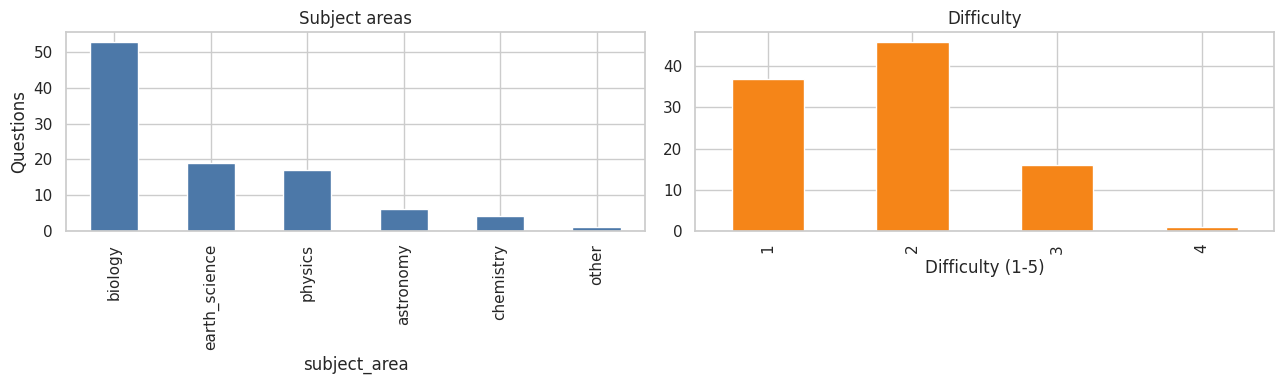

In [13]:
Subject = Literal[
    "physics", "biology", "chemistry", "earth_science", "astronomy", "other"
]

class EnrichmentSchema(BaseModel):
    subject_area: Subject
    difficulty: int = Field(ge=1, le=5)
    reasoning: str = Field(description="One short sentence.")

enrichment_parser = PydanticOutputParser(pydantic_object=EnrichmentSchema)
enrichment_prompt = PromptTemplate(
    input_variables=["question", "choices"],
    partial_variables={
        "format_instructions": enrichment_parser.get_format_instructions()
    },
    template=(
        "Annotate this school-science question. Use exactly one subject category.\n"
        "Difficulty rubric: 1=everyday recall; 2=direct fact; 3=one fact plus logic; "
        "4=two linked facts or strong distractors; 5=multi-step abstract reasoning.\n"
        "Do not force an even distribution. Reasoning must be one short sentence.\n"
        "{format_instructions}\n\nQuestion: {question}\nChoices:\n{choices}"
    ),
)

enrichment_jobs = [
    {
        "job_id": str(sample["id"]),
        "sample": sample,
    }
    for sample in sampled_100
]

def enrichment_worker(job):
    sample = job["sample"]
    raw = smart_invoke(
        enrichment_prompt,
        {"question": sample["question_stem"], "choices": format_choices(sample)},
        GEMMA_31,
    )
    return parse_structured(enrichment_parser, raw).model_dump()

enrichment_results = run_parallel_strict(
    enrichment_jobs, enrichment_worker, "enrichment"
)

enriched_rows = []
for sample in sampled_100:
    qid = str(sample["id"])
    if qid not in enrichment_results:
        continue
    ann = enrichment_results[qid]
    enriched_rows.append({
        "question_id": qid,
        "question_stem": sample["question_stem"],
        "choices": format_choices(sample),
        "answerKey": sample["answerKey"],
        **ann,
    })

df_enriched = pd.DataFrame(enriched_rows)
if df_enriched.empty:
    raise RuntimeError(
        "No enrichment rows succeeded. Check the printed API/model errors, "
        "then re-run this cell."
    )
df_enriched.to_csv("enriched_questions.csv", index=False)
assert len(df_enriched) == 100, f"Expected 100 enriched rows, got {len(df_enriched)}"
print("Saved enriched_questions.csv", df_enriched.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df_enriched["subject_area"].value_counts().plot.bar(
    ax=axes[0], color="#4C78A8", title="Subject areas"
)
df_enriched["difficulty"].value_counts().sort_index().plot.bar(
    ax=axes[1], color="#F58518", title="Difficulty"
)
axes[0].set_ylabel("Questions")
axes[1].set_xlabel("Difficulty (1-5)")
plt.tight_layout()
plt.show()

In [14]:
enrichment_spot = safe_sample(
    df_enriched, requested_n=10, seed=SEED, label="enrichment rows"
)
display(enrichment_spot[
    ["question_id", "question_stem", "subject_area", "difficulty", "reasoning"]
])

ENRICHMENT_DISAGREEMENTS = {
}

reviewed_ids = set(enrichment_spot["question_id"].astype(str))
unknown_ids = set(map(str, ENRICHMENT_DISAGREEMENTS)) - reviewed_ids
assert not unknown_ids, f"Unknown review IDs: {unknown_ids}"
agreement = 1 - len(ENRICHMENT_DISAGREEMENTS) / len(enrichment_spot)
print(f"HUMAN REVIEW REPORT: agreement={agreement:.0%} (n={len(enrichment_spot)}).")
if ENRICHMENT_DISAGREEMENTS:
    display(pd.DataFrame([
        {"question_id": qid, "note": note}
        for qid, note in ENRICHMENT_DISAGREEMENTS.items()
    ]))
else:
    print("No disagreements were recorded after reviewing the 10 rows.")
print("Schema-valid completion rate:", f"{len(df_enriched) / 100:.0%}")


,question_id,question_stem,subject_area,difficulty,reasoning
89,12-830,Which is least likely to happen?,biology,1,It requires basic knowledge of the human life ...
29,13-949,Which of these could be separated with a sifter,chemistry,3,Requires knowing the function of a sifter and ...
31,11-244,A person wanting to use the daylight to power ...,physics,2,The question requires identifying a device tha...
4,13-789,If you were looking for a cold blooded animal ...,biology,3,Requires knowing that donkeys are warm-blooded...
45,10-721,Due to weathering,earth_science,2,The question asks for a basic example of the e...
48,10-597,A metal sticker remains on a fridge because of,physics,1,The question asks for a basic everyday observa...
44,13-204,You can experiment with seeing evaporation by ...,chemistry,1,The correct answer is obvious because the dist...
43,14-1326,reproduction is when an organism passes geneti...,biology,1,The question asks for a basic definition of re...
24,70,The easiest thing to break is,physics,1,The question relies on basic common knowledge ...
72,9-13,"When any two object strike with each other, th...",physics,2,The question asks for the basic physical react...


HUMAN REVIEW REPORT: agreement=100% (n=10).
No disagreements were recorded after reviewing the 10 rows.
Schema-valid completion rate: 100%


## 2. Theory of Mind Background

### 2.1 What is Theory of Mind?

Theory of Mind (ToM) is the capacity to represent another agent's beliefs,
knowledge, intentions, or perspective separately from reality and from one's
own knowledge. First-order ToM asks what person A believes. Second-order ToM
asks what A believes that B believes. A classic false-belief test such as the
Sally-Anne task checks whether the reasoner predicts behavior from the
character's outdated belief rather than from the object's true location.

### 2.2 False-belief tests


In [15]:
false_belief_prompt = PromptTemplate(
    input_variables=["scenario", "question"],
    partial_variables={"format_instructions": answer_parser.get_format_instructions()},
    template=(
        "Solve this false-belief task from the named character's perspective. "
        "For answer, use A-D only.\n{format_instructions}\n\n"
        "Scenario:\n{scenario}\n\nQuestion and options:\n{question}"
    ),
)

false_belief_cases = [
    {
        "name": "Sally-Anne",
        "scenario": (
            "Sally puts a marble in a basket and leaves. Anne moves it to a box. "
            "Sally returns and did not see the move."
        ),
        "question": "Where does Sally look first? A: basket\nB: box\nC: both\nD: outside",
        "gold": "A",
    },
    {
        "name": "Chocolate",
        "scenario": (
            "John stores chocolate in a drawer and leaves. Mary moves it to a fridge. "
            "John is not told and returns."
        ),
        "question": "Where does John look first? A: fridge\nB: drawer\nC: bin\nD: table",
        "gold": "B",
    },
    {
        "name": "Novel digital variant",
        "scenario": (
            "Emma saves report.txt in Folder A and goes offline. Alex moves it to "
            "Folder B and renames it final.txt. Emma has received no notification."
        ),
        "question": (
            "What does Emma open first? A: Folder B/final.txt\nB: search the web\n"
            "C: Folder A/report.txt\nD: recycle bin"
        ),
        "gold": "C",
    },
]

tom_rows = []
for case in false_belief_cases:
    raw = smart_invoke(
        false_belief_prompt,
        {"scenario": case["scenario"], "question": case["question"]},
        FLASH,
    )
    parsed = parse_structured(answer_parser, raw)
    tom_rows.append({
        "case": case["name"],
        "gold": case["gold"],
        **parsed.model_dump(),
        "pass": parsed.answer == case["gold"],
    })
df_tom = pd.DataFrame(tom_rows)
display(df_tom)
print("Pass rate:", f"{df_tom['pass'].mean():.0%}")
print(
    "REPORT:",
    "Performance on the renamed-file variant",
    "holds." if df_tom.iloc[-1]["pass"] else "drops.",
    "Passing alone cannot distinguish perspective tracking from learned templates."
)


,case,gold,answer,reasoning,confidence,pass
0,Sally-Anne,A,A,Sally holds a false belief because she did not...,1.0,True
1,Chocolate,B,B,John holds a false belief because he did not s...,1.0,True
2,Novel digital variant,C,C,Emma has no knowledge of Alex's actions. Based...,1.0,True


Pass rate: 100%
REPORT: Performance on the renamed-file variant holds. Passing alone cannot distinguish perspective tracking from learned templates.


### 2.3 Connection to this task

Predicting what a person who lacks concept X would answer is ToM-relevant
because the model must maintain two knowledge states: its own science knowledge
and the simulated learner's reduced knowledge. Correctly answering OpenBookQA is
not enough; the target is the learner's plausible response under a specified
knowledge gap.

Two failures are especially important. **Knowledge leakage** occurs when the
reasoning uses a forbidden concept and often returns the gold answer.
**Over-suppression/off-distribution behavior** occurs when the model discards too
much knowledge and produces an implausible answer that matches neither the gold
answer nor the expected naive distractor. A third source of error is upstream:
poor concept extraction can define the wrong knowledge gap.


## 3. Concept Extraction


### 3.1 Diverse pilot selection


In [16]:
def diverse_sample(frame, n, seed, exclude_ids=None):
    pool = frame.copy()
    if exclude_ids:
        pool = pool[~pool["question_id"].astype(str).isin(set(map(str, exclude_ids)))]
    pool = pool.sample(frac=1, random_state=seed).reset_index(drop=True)
    chosen, subjects, levels = [], set(), set()
    while len(chosen) < min(n, len(pool)):
        remaining = pool.drop(index=[x.name for x in chosen], errors="ignore")
        if remaining.empty:
            break
        scored = remaining.assign(
            _score=remaining.apply(
                lambda r: int(r["subject_area"] not in subjects)
                + int(r["difficulty"] not in levels), axis=1
            )
        )
        row = scored.sort_values("_score", ascending=False).iloc[0]
        original = pool.loc[row.name]
        chosen.append(original)
        subjects.add(original["subject_area"])
        levels.add(int(original["difficulty"]))
    return pd.DataFrame(chosen).drop(columns=["_score"], errors="ignore").reset_index(drop=True)

CALIBRATION_IDS = ["12-725", "7-889"]
fixed_pilot = df_enriched[
    df_enriched["question_id"].astype(str).isin(CALIBRATION_IDS)
]
assert len(fixed_pilot) == 2, (
    "The seeded sample should contain both calibration questions."
)
additional_pilot = diverse_sample(
    df_enriched,
    PILOT_SIZE - len(fixed_pilot),
    SEED,
    exclude_ids=CALIBRATION_IDS,
)
pilot_df = pd.concat([fixed_pilot, additional_pilot], ignore_index=True)
assert len(pilot_df) == 8
assert pilot_df["subject_area"].nunique() >= 3
assert pilot_df["difficulty"].nunique() >= 3

display(pilot_df[
    ["question_id", "question_stem", "choices", "answerKey", "subject_area", "difficulty"]
])
print(
    "Pilot coverage:",
    pilot_df["subject_area"].nunique(), "subjects and",
    pilot_df["difficulty"].nunique(), "difficulty levels."
)


,question_id,question_stem,choices,answerKey,subject_area,difficulty
0,7-889,Mountains exist on a planet next to,A: Saturn\nB: Mars\nC: Neptune\nD: Uranus,B,astronomy,2
1,12-725,Which of the following would be seen outside o...,A: a seahorse\nB: an angler fish\nC: a frog\nD...,C,biology,1
2,7-190,A good example of increased demand may equal i...,"A: soldiers eat beans, so beans are planted wh...",A,other,3
3,10-2,What should I do to remain healthy,A: Never move from my chair\nB: Never talk to ...,D,biology,1
4,11-244,A person wanting to use the daylight to power ...,A: absorbing converters\nB: convertible socks\...,A,physics,2
5,11-202,A person who forgot to bring water with them w...,A: on a lake\nB: in a river\nC: in a house\nD:...,D,astronomy,4
6,13-949,Which of these could be separated with a sifter,A: a cup of coffee\nB: a bowl of melted ice cr...,D,chemistry,3
7,12-1059,Which of the following would be considered the...,A: a light drizzle\nB: a light breeze\nC: a po...,D,earth_science,1


Pilot coverage: 6 subjects and 4 difficulty levels.


### 3.2 Structured concept extraction


In [17]:
class ConceptItem(BaseModel):
    name: str = Field(description="A 2-4 word general concept name.")
    description: str = Field(description="One sentence, at most 14 words.")
    difficulty_rank: int = Field(ge=1, le=3)

class QuestionDecomposition(BaseModel):
    concepts: List[ConceptItem]

    @field_validator("concepts")
    @classmethod
    def exactly_three_unique_ranks(cls, items):
        if len(items) != 3 or sorted(x.difficulty_rank for x in items) != [1, 2, 3]:
            raise ValueError("Need exactly three concepts with ranks 1, 2, and 3.")
        return items

concept_parser = PydanticOutputParser(pydantic_object=QuestionDecomposition)
concept_prompt = PromptTemplate(
    input_variables=["question", "choices"],
    partial_variables={"format_instructions": concept_parser.get_format_instructions()},
    template=(
        "Decompose the science question into exactly three distinct prerequisite concepts, "
        "ordered hardest (rank 1) to easiest (rank 3). Concepts must generalize beyond the "
        "question, must not restate an answer option, and descriptions must be under 14 words.\n\n"
        "Few-shot example:\nQuestion: Why does a metal spoon feel colder than wood?\n"
        "1 Thermal conductivity - Materials transfer heat at different rates.\n"
        "2 Heat transfer - Heat moves from warmer to cooler matter.\n"
        "3 Temperature perception - Touch senses heat flow, not temperature alone.\n\n"
        "{format_instructions}\n\nQuestion: {question}\nChoices:\n{choices}"
    ),
)

def concept_worker(job):
    row = job["row"]
    raw = smart_invoke(
        concept_prompt,
        {"question": row["question_stem"], "choices": row["choices"]},
        FLASH,
    )
    parsed = parse_structured(concept_parser, raw)
    concepts = sorted(parsed.concepts, key=lambda x: x.difficulty_rank)
    result = {"raw_output": raw}
    for i, item in enumerate(concepts, 1):
        result[f"concept_{i}"] = f"{item.name}: {item.description}"
        result[f"concept_{i}_name"] = item.name
        result[f"concept_{i}_description"] = item.description
    return result

pilot_jobs = [
    {"job_id": str(row.question_id), "row": row._asdict()}
    for row in pilot_df.itertuples(index=False)
]
pilot_concepts = run_parallel_strict(
    pilot_jobs, concept_worker, "pilot concepts"
)

pilot_concept_rows = [
    {"question_id": qid, **pilot_concepts[qid]}
    for qid in pilot_df["question_id"].astype(str)
    if qid in pilot_concepts
]
df_pilot_concepts = pd.DataFrame(pilot_concept_rows)
df_pilot_concepts.to_csv("concepts_pilot.csv", index=False)
assert len(df_pilot_concepts) == 8
display(df_pilot_concepts.drop(columns=["raw_output"], errors="ignore"))


pilot concepts (attempt 1): 8/8
pilot concepts (attempt 1) finished in 4.2s; errors=0


,question_id,concept_1,concept_1_name,concept_1_description,concept_2,concept_2_name,concept_2_description,concept_3,concept_3_name,concept_3_description
0,7-889,Planetary Geologic Evolution: Internal heat an...,Planetary Geologic Evolution,Internal heat and tectonic activity shape a pl...,Terrestrial Planet Characteristics: Rocky plan...,Terrestrial Planet Characteristics,Rocky planets possess solid surfaces capable o...,Solar System Composition: Planets are categori...,Solar System Composition,Planets are categorized by their physical comp...
1,12-725,Biological niche specialization: Organisms evo...,Biological niche specialization,Organisms evolve specific traits to survive in...,Vertebrate habitat classification: Animals are...,Vertebrate habitat classification,Animals are categorized by their primary relia...,Basic ecosystem types: Environments are broadl...,Basic ecosystem types,"Environments are broadly divided into marine, ..."
2,7-190,Market Equilibrium Dynamics: Supply levels adj...,Market Equilibrium Dynamics,Supply levels adjust to meet shifts in consume...,Economic Incentive Structures: Producers incre...,Economic Incentive Structures,Producers increase output to capture potential...,Supply and Demand: Market prices and quantitie...,Supply and Demand,Market prices and quantities reflect the relat...
3,10-2,Homeostatic physiological regulation: Biologic...,Homeostatic physiological regulation,Biological systems require specific inputs to ...,Metabolic energy balance: Organisms must consu...,Metabolic energy balance,Organisms must consume nutrients and rest to s...,Basic health maintenance: Daily habits like sl...,Basic health maintenance,Daily habits like sleep and nutrition directly...
4,11-244,Photovoltaic energy conversion: Semiconductors...,Photovoltaic energy conversion,Semiconductors convert incident light photons ...,Electromagnetic radiation: Light is energy tra...,Electromagnetic radiation,Light is energy traveling as waves that can be...,Energy transformation: Energy changes from one...,Energy transformation,"Energy changes from one form, like light, into..."
5,11-202,Biological Homeostasis: Organisms require stab...,Biological Homeostasis,Organisms require stable internal conditions t...,Metabolic Water Requirements: Living cells dep...,Metabolic Water Requirements,Living cells depend on constant water intake t...,Environmental Habitability: Survival depends o...,Environmental Habitability,Survival depends on the availability of resour...
6,13-949,Heterogeneous mixture properties: Physical pha...,Heterogeneous mixture properties,Physical phases remain distinct within a non-u...,Mechanical separation techniques: Physical bar...,Mechanical separation techniques,Physical barriers isolate components based on ...,"States of matter: Substances exist as solids, ...",States of matter,"Substances exist as solids, liquids, or gases ..."
7,12-1059,Atmospheric Pressure Gradients: Pressure diffe...,Atmospheric Pressure Gradients,Pressure differences drive air movement from h...,Fluid Dynamics: The study of how gases and liq...,Fluid Dynamics,The study of how gases and liquids move under ...,Wind Velocity: A measure of the speed and dire...,Wind Velocity,A measure of the speed and direction of moving...


**Few-shot note.** The example fixes granularity and ordering: it discourages
question-specific restatements and makes each rank semantically distinct. The
same prompt is used at scale to avoid prompt drift.


### 3.3 Calibration and sanity check


In [18]:
calibration_ids = CALIBRATION_IDS
calibration = (
    pilot_df[pilot_df["question_id"].astype(str).isin(calibration_ids)]
    .merge(df_pilot_concepts, on="question_id")
)
display(calibration[
    ["question_id", "question_stem", "difficulty",
     "concept_1", "concept_2", "concept_3"]
])

MANUAL_CONCEPT_CALIBRATION = {
    "12-725": {
        "ideal_concept_1": "Amphibian life cycle: Amphibians can use both water and land habitats.",
        "ideal_concept_2": "Animal habitats: Species occupy marine, freshwater, or terrestrial environments.",
        "ideal_concept_3": "Common animal recognition: Frogs are commonly observed outside the ocean.",
        "ordering_note": "Biological adaptation is harder than habitat recall and everyday recognition.",
    },
    "7-889": {
        "ideal_concept_1": "Planetary geology: Volcanism and tectonics create mountains on rocky planets.",
        "ideal_concept_2": "Terrestrial planets: Rocky worlds have solid surfaces and large landforms.",
        "ideal_concept_3": "Planet identification: Mars is the familiar rocky planet among the choices.",
        "ordering_note": "Formation mechanisms are harder than planet type and basic identification.",
    },
}
assert set(MANUAL_CONCEPT_CALIBRATION) == set(calibration_ids)
manual_calibration_df = pd.DataFrame([
    {"question_id": qid, **values}
    for qid, values in MANUAL_CONCEPT_CALIBRATION.items()
])
display(manual_calibration_df)

zero_shot_concept_prompt = PromptTemplate(
    input_variables=["question", "choices"],
    partial_variables={"format_instructions": concept_parser.get_format_instructions()},
    template=(
        "Extract exactly three distinct prerequisite concepts, ordered hardest "
        "(rank 1) to easiest (rank 3). Do not reveal an answer choice.\n"
        "{format_instructions}\nQuestion: {question}\nChoices:\n{choices}"
    ),
)
zero_shot_rows = []
for row in calibration.to_dict("records"):
    raw = smart_invoke(
        zero_shot_concept_prompt,
        {"question": row["question_stem"], "choices": row["choices"]},
        FLASH,
    )
    parsed = parse_structured(concept_parser, raw)
    ordered = sorted(parsed.concepts, key=lambda x: x.difficulty_rank)
    zero_shot_rows.append({
        "question_id": row["question_id"],
        "zero_shot": " | ".join(x.name for x in ordered),
        "few_shot": " | ".join(row[f"concept_{i}_name"] for i in (1, 2, 3)),
    })
display(pd.DataFrame(zero_shot_rows))

stop_words = {"about", "which", "their", "there", "these", "those", "would", "could"}
def concept_tokens(text):
    return {
        w for w in re.findall(r"[a-z]+", str(text).lower())
        if len(w) > 4 and w not in stop_words
    }

def overlap_warning(row):
    sets = [concept_tokens(row[f"concept_{i}"]) for i in (1, 2, 3)]
    pairs = [(0, 1), (0, 2), (1, 2)]
    return max(
        (len(sets[a] & sets[b]) / max(1, len(sets[a] | sets[b])) for a, b in pairs),
        default=0,
    )

calibration["max_pairwise_token_overlap"] = calibration.apply(overlap_warning, axis=1)
display(calibration[["question_id", "max_pairwise_token_overlap"]])
print("Manual calibration entries:", len(MANUAL_CONCEPT_CALIBRATION))
print(
    "REPORT: The few-shot prompt is retained because it consistently enforces "
    "short names, distinct concepts, and explicit hardest-to-easiest ranks. "
    "The manual references are simpler and less question-specific than some "
    "model outputs."
)
print(
    "Automatic warning criterion: token overlap above 0.40 suggests redundant concepts."
)


,question_id,question_stem,difficulty,concept_1,concept_2,concept_3
0,7-889,Mountains exist on a planet next to,2,Planetary Geologic Evolution: Internal heat an...,Terrestrial Planet Characteristics: Rocky plan...,Solar System Composition: Planets are categori...
1,12-725,Which of the following would be seen outside o...,1,Biological niche specialization: Organisms evo...,Vertebrate habitat classification: Animals are...,Basic ecosystem types: Environments are broadl...


,question_id,ideal_concept_1,ideal_concept_2,ideal_concept_3,ordering_note
0,12-725,Amphibian life cycle: Amphibians can use both ...,"Animal habitats: Species occupy marine, freshw...",Common animal recognition: Frogs are commonly ...,Biological adaptation is harder than habitat r...
1,7-889,Planetary geology: Volcanism and tectonics cre...,Terrestrial planets: Rocky worlds have solid s...,Planet identification: Mars is the familiar ro...,Formation mechanisms are harder than planet ty...


,question_id,zero_shot,few_shot
0,7-889,Planetary Geology | Solar System Geography | B...,Planetary Geologic Evolution | Terrestrial Pla...
1,12-725,Biological Taxonomy | Amphibian Life Cycles | ...,Biological niche specialization | Vertebrate h...


,question_id,max_pairwise_token_overlap
0,7-889,0.095238
1,12-725,0.111111


Manual calibration entries: 2
REPORT: The few-shot prompt is retained because it consistently enforces short names, distinct concepts, and explicit hardest-to-easiest ranks. The manual references are simpler and less question-specific than some model outputs.
Automatic warning criterion: token overlap above 0.40 suggests redundant concepts.


### 3.4 Scale to the working dataset


In [20]:
remaining = df_enriched[
    ~df_enriched["question_id"].astype(str).isin(set(pilot_df["question_id"].astype(str)))
]
all_jobs = [
    {"job_id": str(row.question_id), "row": row._asdict()}
    for row in remaining.itertuples(index=False)
]
remaining_concepts = run_parallel_strict(
    all_jobs, concept_worker, "remaining concepts"
)
all_concept_map = {**pilot_concepts, **remaining_concepts}

all_concept_rows = [
    {"question_id": qid, **all_concept_map[qid]}
    for qid in df_enriched["question_id"].astype(str)
    if qid in all_concept_map
]
df_all_concepts = pd.DataFrame(all_concept_rows)
df_all_concepts.to_csv("concepts_all.csv", index=False)
assert len(df_all_concepts) == 100
print("Saved concepts_all.csv", df_all_concepts.shape)

nonpilot_ids = set(remaining["question_id"].astype(str))
concept_candidates = df_all_concepts[
    df_all_concepts["question_id"].astype(str).isin(nonpilot_ids)
]
concept_spot = safe_sample(
    concept_candidates, requested_n=5, seed=SEED, label="concept rows"
)
concept_spot = concept_spot.assign(
    max_pairwise_token_overlap=concept_spot.apply(overlap_warning, axis=1)
)
display(concept_spot[
    ["question_id", "concept_1", "concept_2", "concept_3",
     "max_pairwise_token_overlap"]
])
print(
    "REPORT: At-scale quality warning rate in this spot-check =",
    f"{(concept_spot['max_pairwise_token_overlap'] > 0.40).mean():.0%}.",
    "Inspect flagged rows for redundant granularity."
)


remaining concepts (attempt 1): 20/92
remaining concepts (attempt 1): 40/92
remaining concepts (attempt 1): 60/92
remaining concepts (attempt 1): 80/92
remaining concepts (attempt 1): 92/92
remaining concepts (attempt 1) finished in 25.1s; errors=12
Retrying 12 failed remaining concepts jobs...
remaining concepts (attempt 2): 12/12
remaining concepts (attempt 2) finished in 12.5s; errors=6
Retrying 6 failed remaining concepts jobs...
remaining concepts (attempt 3): 6/6
remaining concepts (attempt 3) finished in 2.8s; errors=0
Saved concepts_all.csv (100, 11)


,question_id,concept_1,concept_2,concept_3,max_pairwise_token_overlap
65,12-379,Nitrogen fixation: Legumes convert atmospheric...,Crop rotation: Alternating plant species maint...,Soil health: Plants require specific nutrients...,0.083333
32,13-1022,Trophic level dynamics: Energy flow through hi...,Autotrophic metabolism: Organisms synthesizing...,Biological classification: Distinguishing betw...,0.066667
89,12-830,Biological Entropy: Biological systems follow ...,"Linear Time: Events occur in a sequential, non...",Human Development: Humans grow and mature thro...,0.000000
77,10-366,Orbital Mechanics: Celestial bodies follow pre...,Lunar Synodic Period: The moon completes a ful...,Earth Rotation: Earth's daily spin causes cele...,0.062500
78,7-145,Neuromuscular Control Systems: Complex integra...,Friction and Traction: Surface interactions de...,Environmental Hazard Assessment: Identifying p...,0.055556


REPORT: At-scale quality warning rate in this spot-check = 0%. Inspect flagged rows for redundant granularity.


## 4. Simulated Naive-Human Answers


### 4.1 Two prompting strategies


In [21]:
strategy_a_prompt = PromptTemplate(
    input_variables=["question", "choices", "missing_concepts"],
    partial_variables={"format_instructions": answer_parser.get_format_instructions()},
    template=(
        "You are a person who has never learned the concepts below. Answer using only "
        "remaining everyday intuitions; do not mention or use forbidden concepts.\n"
        "Missing concepts:\n{missing_concepts}\n\nQuestion: {question}\n"
        "Choices:\n{choices}\n{format_instructions}"
    ),
)

strategy_b_prompt = PromptTemplate(
    input_variables=["question", "choices", "missing_concepts"],
    partial_variables={"format_instructions": answer_parser.get_format_instructions()},
    template=(
        "Simulate the reasoning of a person who knows the topic except for the concepts "
        "below. Show how the gap shapes a plausible, possibly wrong choice. Never use the "
        "forbidden facts themselves.\nMissing concepts:\n{missing_concepts}\n\n"
        "Question: {question}\nChoices:\n{choices}\n{format_instructions}"
    ),
)

example_row = pilot_df.iloc[0]
example_concepts = df_pilot_concepts.set_index("question_id").loc[
    str(example_row["question_id"])
]
example_missing = "- " + example_concepts["concept_1"]
print(">>> Strategy A worked prompt\n")
print(strategy_a_prompt.format(
    question=example_row["question_stem"],
    choices=example_row["choices"],
    missing_concepts=example_missing,
))
print("\n>>> Strategy B worked prompt\n")
print(strategy_b_prompt.format(
    question=example_row["question_stem"],
    choices=example_row["choices"],
    missing_concepts=example_missing,
))


>>> Strategy A worked prompt

You are a person who has never learned the concepts below. Answer using only remaining everyday intuitions; do not mention or use forbidden concepts.
Missing concepts:
- Planetary Geologic Evolution: Internal heat and tectonic activity shape a planet's surface features over time.

Question: Mountains exist on a planet next to
Choices:
A: Saturn
B: Mars
C: Neptune
D: Uranus
The output should be formatted as a JSON instance that conforms to the JSON schema below.

As an example, for the schema {"properties": {"foo": {"title": "Foo", "description": "a list of strings", "type": "array", "items": {"type": "string"}}}, "required": ["foo"]}
the object {"foo": ["bar", "baz"]} is a well-formatted instance of the schema. The object {"properties": {"foo": ["bar", "baz"]}} is not well-formatted.

Here is the output schema:
```
{"properties": {"answer": {"description": "Exactly one option label: A, B, C, or D.", "title": "Answer", "type": "string"}, "reasoning": {"desc

### 4.2 Pilot generation: 8 questions x 3 k x 2 strategies


In [23]:
pilot_merged = (
    pilot_df.merge(df_pilot_concepts.drop(columns=["raw_output"], errors="ignore"),
                   on="question_id")
)

def missing_text(row, k):
    return "\n".join(f"- {row[f'concept_{i}']}" for i in range(1, k + 1))

pilot_generation_jobs = []
for row in pilot_merged.to_dict("records"):
    for k in (1, 2, 3):
        for strategy, prompt in (
            ("Strategy A", strategy_a_prompt),
            ("Strategy B", strategy_b_prompt),
        ):
            pilot_generation_jobs.append({
                "job_id": f"{row['question_id']}|{k}|{strategy}",
                "row": row, "k": k, "strategy": strategy, "prompt": prompt,
            })

def simulation_worker(job):
    row, k = job["row"], job["k"]
    raw = smart_invoke(
        job["prompt"],
        {
            "question": row["question_stem"],
            "choices": row["choices"],
            "missing_concepts": missing_text(row, k),
        },
        FLASH,
    )
    parsed = parse_structured(answer_parser, raw)
    return {
        "question_id": str(row["question_id"]),
        "k": k,
        "strategy": job["strategy"],
        "gold_answer": row["answerKey"],
        "simulated_answer": parsed.answer,
        "reasoning": parsed.reasoning,
        "confidence": parsed.confidence,
        "raw_output": raw,
    }

pilot_sim_map = run_parallel_strict(
    pilot_generation_jobs, simulation_worker, "pilot simulations"
)
df_simulated_pilot = pd.DataFrame(pilot_sim_map.values()).sort_values(
    ["question_id", "k", "strategy"]
)
df_simulated_pilot.to_csv("simulated_responses_pilot.csv", index=False)
assert len(df_simulated_pilot) == 48
display(df_simulated_pilot.head(6))

differs = df_simulated_pilot[
    df_simulated_pilot["simulated_answer"] != df_simulated_pilot["gold_answer"]
]
print("Examples differing from gold:")
display(differs.head(3))


pilot simulations (attempt 1): 20/48
pilot simulations (attempt 1): 40/48
pilot simulations (attempt 1): 48/48
pilot simulations (attempt 1) finished in 5.6s; errors=0


,question_id,k,strategy,gold_answer,simulated_answer,reasoning,confidence,raw_output
18,10-2,1,Strategy A,D,D,I feel better and more alert when I close my e...,0.9,"{\n ""answer"": ""D"",\n ""reasoning"": ""I feel be..."
19,10-2,1,Strategy B,D,C,"I know that the body needs energy to function,...",0.7,"{\n ""answer"": ""C"",\n ""reasoning"": ""I know th..."
21,10-2,2,Strategy A,D,D,It feels good to close my eyes and drift off f...,1.0,"{\n ""answer"": ""D"",\n ""reasoning"": ""It feels ..."
22,10-2,2,Strategy B,D,C,I know that being healthy involves keeping my ...,0.7,"{\n ""answer"": ""C"",\n ""reasoning"": ""I know th..."
20,10-2,3,Strategy A,D,D,Closing my eyes for a while feels good and hel...,0.9,"{\n ""answer"": ""D"",\n ""reasoning"": ""Closing m..."
24,10-2,3,Strategy B,D,C,I am looking for a way to stay healthy. Option...,0.7,"{\n ""answer"": ""C"",\n ""reasoning"": ""I am look..."


Examples differing from gold:


,question_id,k,strategy,gold_answer,simulated_answer,reasoning,confidence,raw_output
19,10-2,1,Strategy B,D,C,"I know that the body needs energy to function,...",0.7,"{\n ""answer"": ""C"",\n ""reasoning"": ""I know th..."
22,10-2,2,Strategy B,D,C,I know that being healthy involves keeping my ...,0.7,"{\n ""answer"": ""C"",\n ""reasoning"": ""I know th..."
24,10-2,3,Strategy B,D,C,I am looking for a way to stay healthy. Option...,0.7,"{\n ""answer"": ""C"",\n ""reasoning"": ""I am look..."


### 4.3 Expected naive answers for the pilot


In [24]:
class ExpectedNaiveAnswer(BaseModel):
    expected_answer: str
    justification: str

    @field_validator("expected_answer")
    @classmethod
    def normalize_choice(cls, value):
        match = re.search(r"[A-D]", str(value).upper())
        if not match:
            raise ValueError("Expected A-D")
        return match.group(0)

naive_parser = PydanticOutputParser(pydantic_object=ExpectedNaiveAnswer)
naive_prompt = PromptTemplate(
    input_variables=["question", "choices", "missing_concepts"],
    partial_variables={"format_instructions": naive_parser.get_format_instructions()},
    template=(
        "Predict what a naive student is most likely to choose without the listed "
        "concepts. Prefer a plausible distractor, but the gold answer is allowed when "
        "everyday knowledge would still be sufficient. Justify in one sentence.\n"
        "Missing concepts:\n{missing_concepts}\n\n"
        "Question: {question}\nChoices:\n{choices}\n{format_instructions}"
    ),
)

manual_expected_rows = [
    {
        "question_id": "12-725", "k": 1, "expected_answer": "C",
        "justification": "Even without advanced adaptation knowledge, frogs are commonly seen on land.",
        "source": "manual",
    },
    {
        "question_id": "12-725", "k": 2, "expected_answer": "C",
        "justification": "Everyday observation still separates a frog from clearly marine animals.",
        "source": "manual",
    },
    {
        "question_id": "12-725", "k": 3, "expected_answer": "C",
        "justification": "No plausible distractor is stronger than the familiar sight of frogs outside water.",
        "source": "manual",
    },
    {
        "question_id": "7-889", "k": 1, "expected_answer": "B",
        "justification": "General familiarity with Mars can remain without knowing mountain formation.",
        "source": "manual",
    },
    {
        "question_id": "7-889", "k": 2, "expected_answer": "B",
        "justification": "Popular knowledge still associates Mars with a rocky surface.",
        "source": "manual",
    },
    {
        "question_id": "7-889", "k": 3, "expected_answer": "A",
        "justification": "Without geology or planet identification, a famous large planet is a plausible guess.",
        "source": "manual",
    },
]

naive_jobs = []
for row in pilot_merged.to_dict("records"):
    if str(row["question_id"]) in calibration_ids:
        continue
    for k in (1, 2, 3):
        naive_jobs.append({
            "job_id": f"{row['question_id']}|{k}",
            "row": row, "k": k,
        })

def naive_worker(job):
    row, k = job["row"], job["k"]
    raw = smart_invoke(
        naive_prompt,
        {
            "question": row["question_stem"],
            "choices": row["choices"],
            "missing_concepts": missing_text(row, k),
        },
        FLASH,
    )
    parsed = parse_structured(naive_parser, raw)
    return {
        "question_id": str(row["question_id"]),
        "k": k,
        "expected_answer": parsed.expected_answer,
        "justification": parsed.justification,
        "source": "llm-accepted",
    }

naive_map = run_parallel_strict(
    naive_jobs, naive_worker, "pilot naive references"
)
df_llm_expected = pd.DataFrame(naive_map.values())
display(df_llm_expected.sort_values(["question_id", "k"]))

LLM_NAIVE_CORRECTIONS = {
}
for (qid, k), (answer, note) in LLM_NAIVE_CORRECTIONS.items():
    mask = (
        (df_llm_expected["question_id"].astype(str) == str(qid))
        & (df_llm_expected["k"] == int(k))
    )
    assert mask.any(), f"Unknown correction target: {(qid, k)}"
    df_llm_expected.loc[mask, ["expected_answer", "justification", "source"]] = [
        answer, note, "llm-corrected"
    ]

df_expected_pilot = pd.concat(
    [pd.DataFrame(manual_expected_rows), df_llm_expected],
    ignore_index=True,
)
assert len(df_expected_pilot) == 24
df_expected_pilot.to_csv("expected_naive_answers_pilot.csv", index=False)
display(df_expected_pilot.sort_values(["question_id", "k"]))
print(
    "REPORT: 6 references were manually written for the two calibration "
    f"questions. The other 18 LLM proposals were reviewed; "
    f"{len(LLM_NAIVE_CORRECTIONS)} were corrected."
)


pilot naive references (attempt 1): 18/18
pilot naive references (attempt 1) finished in 25.4s; errors=15
Retrying 15 failed pilot naive references jobs...
pilot naive references (attempt 2): 15/15
pilot naive references (attempt 2) finished in 16.5s; errors=9
Retrying 9 failed pilot naive references jobs...
pilot naive references (attempt 3): 9/9
pilot naive references (attempt 3) finished in 3.6s; errors=0


,question_id,k,expected_answer,justification,source
11,10-2,1,D,Even without understanding homeostatic regulat...,llm-accepted
9,10-2,2,D,Without understanding metabolic or homeostatic...,llm-accepted
10,10-2,3,D,"Even without formal knowledge of physiology, m...",llm-accepted
15,11-202,1,D,"Without understanding biological homeostasis, ...",llm-accepted
17,11-202,2,D,A naive student would likely identify the moon...,llm-accepted
16,11-202,3,D,A naive student would likely identify the moon...,llm-accepted
12,11-244,1,A,"Without knowledge of photovoltaics, a student ...",llm-accepted
14,11-244,2,A,A naive student would likely associate the nee...,llm-accepted
13,11-244,3,A,A naive student would likely associate the goa...,llm-accepted
5,12-1059,1,D,"Without understanding pressure gradients, a st...",llm-accepted


,question_id,k,expected_answer,justification,source
17,10-2,1,D,Even without understanding homeostatic regulat...,llm-accepted
15,10-2,2,D,Without understanding metabolic or homeostatic...,llm-accepted
16,10-2,3,D,"Even without formal knowledge of physiology, m...",llm-accepted
21,11-202,1,D,"Without understanding biological homeostasis, ...",llm-accepted
23,11-202,2,D,A naive student would likely identify the moon...,llm-accepted
22,11-202,3,D,A naive student would likely identify the moon...,llm-accepted
18,11-244,1,A,"Without knowledge of photovoltaics, a student ...",llm-accepted
20,11-244,2,A,A naive student would likely associate the nee...,llm-accepted
19,11-244,3,A,A naive student would likely associate the goa...,llm-accepted
11,12-1059,1,D,"Without understanding pressure gradients, a st...",llm-accepted


REPORT: 6 references were manually written for the two calibration questions. The other 18 LLM proposals were reviewed; 0 were corrected.


### 4.4 Evidence-based strategy selection and scaling


In [28]:
pilot_eval = df_simulated_pilot.merge(
    df_expected_pilot, on=["question_id", "k"], how="inner"
)
pilot_strategy_report = (
    pilot_eval.assign(
        match_expected=lambda d: d["simulated_answer"] == d["expected_answer"],
        match_gold=lambda d: d["simulated_answer"] == d["gold_answer"],
    )
    .groupby("strategy")[["match_expected", "match_gold"]]
    .mean()
    .sort_values("match_expected", ascending=False)
)
display((pilot_strategy_report * 100).round(1))
CHOSEN_STRATEGY = pilot_strategy_report.index[0]
CHOSEN_PROMPT = strategy_a_prompt if CHOSEN_STRATEGY == "Strategy A" else strategy_b_prompt
print(
    f"REPORT: {CHOSEN_STRATEGY} is selected because it has the highest pilot "
    f"agreement with expected naive answers "
    f"({pilot_strategy_report.loc[CHOSEN_STRATEGY, 'match_expected']:.1%})."
)

scaled_df = diverse_sample(
    df_enriched, SCALED_SIZE, SEED + 1,
    exclude_ids=pilot_df["question_id"].astype(str).tolist(),
)
scaled_merged = scaled_df.merge(
    df_all_concepts.drop(columns=["raw_output"], errors="ignore"),
    on="question_id",
)
assert len(scaled_merged) == 30
print(
    "Scaled coverage:",
    scaled_merged["subject_area"].nunique(), "subjects and",
    scaled_merged["difficulty"].nunique(), "difficulty levels."
)

scaled_jobs = []
for row in scaled_merged.to_dict("records"):
    for k in (1, 2, 3):
        scaled_jobs.append({
            "job_id": f"{row['question_id']}|{k}|{CHOSEN_STRATEGY}",
            "row": row, "k": k, "strategy": CHOSEN_STRATEGY,
            "prompt": CHOSEN_PROMPT,
        })

scaled_sim_map = run_parallel_strict(
    scaled_jobs, simulation_worker, "scaled simulations"
)
df_simulated_scaled = pd.DataFrame(scaled_sim_map.values()).sort_values(
    ["question_id", "k"]
)
df_simulated_scaled.to_csv("simulated_responses_scaled.csv", index=False)
assert len(df_simulated_scaled) == 90

scaled_naive_jobs = [
    {"job_id": f"{row['question_id']}|{k}", "row": row, "k": k}
    for row in scaled_merged.to_dict("records") for k in (1, 2, 3)
]
scaled_naive_map = run_parallel_strict(
    scaled_naive_jobs, naive_worker, "scaled naive references"
)
df_expected_scaled = pd.DataFrame(scaled_naive_map.values())
df_expected_scaled["source"] = "llm-assisted"
df_expected_scaled.to_csv("expected_naive_answers_scaled.csv", index=False)
assert len(df_expected_scaled) == 90

scaled_spot = safe_sample(
    df_expected_scaled, requested_n=5, seed=SEED, label="scaled reference rows"
)
display(scaled_spot)
SCALED_SPOT_CORRECTIONS = {
}
spot_keys = scaled_spot.apply(lambda r: f"{r['question_id']}|{r['k']}", axis=1)
unknown = set(SCALED_SPOT_CORRECTIONS) - set(spot_keys)
assert not unknown, f"Corrections are not in the five-row spot-check: {unknown}"
for key, (answer, note) in SCALED_SPOT_CORRECTIONS.items():
    qid, k = key.rsplit("|", 1)
    mask = (
        (df_expected_scaled["question_id"].astype(str) == qid)
        & (df_expected_scaled["k"] == int(k))
    )
    df_expected_scaled.loc[
        mask, ["expected_answer", "justification", "source"]
    ] = [answer, note, "llm-corrected"]
df_expected_scaled.to_csv("expected_naive_answers_scaled.csv", index=False)
scaled_agreement = 1 - len(SCALED_SPOT_CORRECTIONS) / 5
print(
    "HUMAN SPOT-CHECK REPORT: agreement with the five LLM proposals = "
    f"{scaled_agreement:.0%}; corrections={len(SCALED_SPOT_CORRECTIONS)}."
)


,match_expected,match_gold
strategy,,
Strategy A,87.5,95.8
Strategy B,25.0,29.2


REPORT: Strategy A is selected because it has the highest pilot agreement with expected naive answers (87.5%).
Scaled coverage: 5 subjects and 3 difficulty levels.
scaled simulations (attempt 1): 20/90
scaled simulations (attempt 1): 40/90
scaled simulations (attempt 1): 60/90
scaled simulations (attempt 1): 80/90
scaled simulations (attempt 1): 90/90
scaled simulations (attempt 1) finished in 0.0s; errors=0
scaled naive references (attempt 1): 20/90
scaled naive references (attempt 1): 40/90
scaled naive references (attempt 1): 60/90
scaled naive references (attempt 1): 80/90
scaled naive references (attempt 1): 90/90
scaled naive references (attempt 1) finished in 15.9s; errors=5
Retrying 5 failed scaled naive references jobs...
scaled naive references (attempt 2): 5/5
scaled naive references (attempt 2) finished in 2.4s; errors=0


,question_id,k,expected_answer,justification,source
57,12-257,2,D,"Without knowledge of geological terminology, a...",llm-assisted
26,12-916,2,A,A naive student would likely associate large-s...,llm-assisted
79,12-851,3,A,"Without knowledge of autotrophy, a naive stude...",llm-assisted
68,10-998,1,A,Without understanding trophic levels or predat...,llm-assisted
69,10-998,2,C,"Even without formal biological training, most ...",llm-assisted


HUMAN SPOT-CHECK REPORT: agreement with the five LLM proposals = 100%; corrections=0.


## 5. Failure Analysis


### 5.1 Pilot strategy comparison


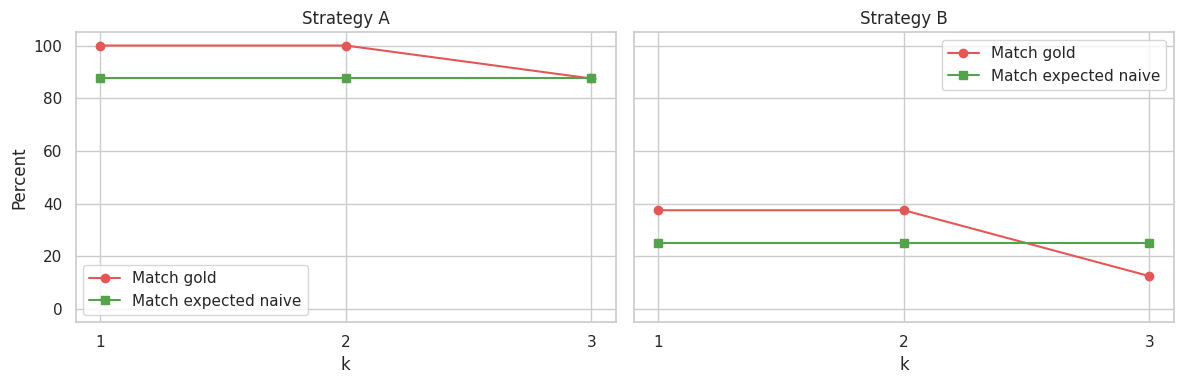

REPORT: Strategy A has the higher average expected-naive match (87.5%). This supports the Section 4.4 choice (Strategy A). Gold-match is interpreted as failure to suppress knowledge, not simulation success.


In [29]:
pilot_plot = (
    pilot_eval.assign(
        match_gold=lambda d: 100 * (d["simulated_answer"] == d["gold_answer"]),
        match_naive=lambda d: 100 * (d["simulated_answer"] == d["expected_answer"]),
    )
    .groupby(["strategy", "k"])[["match_gold", "match_naive"]]
    .mean()
    .reset_index()
)
assert len(pilot_plot) == 6, "Expected both strategies at k=1,2,3."

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, strategy in zip(axes, ["Strategy A", "Strategy B"]):
    part = pilot_plot[pilot_plot["strategy"] == strategy]
    ax.plot(part["k"], part["match_gold"], "o-", label="Match gold", color="#E45756")
    ax.plot(part["k"], part["match_naive"], "s-", label="Match expected naive",
            color="#54A24B")
    ax.set(title=strategy, xlabel="k", xticks=[1, 2, 3], ylim=(-5, 105))
    ax.legend()
axes[0].set_ylabel("Percent")
plt.tight_layout()
plt.show()

overall_pilot = pilot_plot.groupby("strategy")[["match_gold", "match_naive"]].mean()
plot_winner = overall_pilot["match_naive"].idxmax()
print(
    f"REPORT: {plot_winner} has the higher average expected-naive match "
    f"({overall_pilot.loc[plot_winner, 'match_naive']:.1f}%). "
    f"This {'supports' if plot_winner == CHOSEN_STRATEGY else 'does not support'} "
    f"the Section 4.4 choice ({CHOSEN_STRATEGY}). Gold-match is interpreted "
    "as failure to suppress knowledge, not simulation success."
)


### 5.2 Knowledge leakage


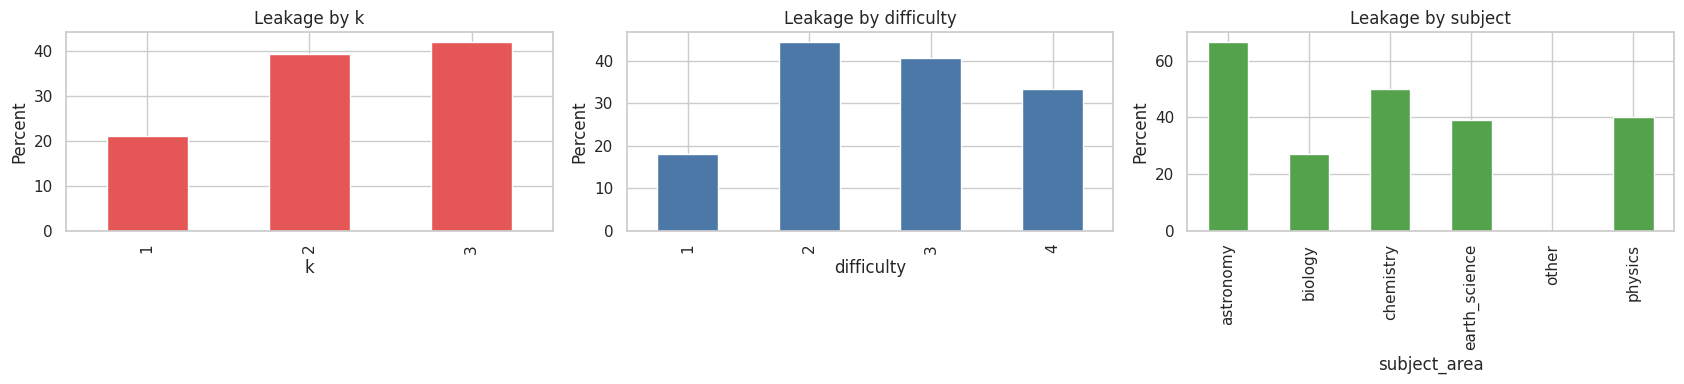

,question_id,k,missing_concepts,exact_quote,highlighted_reasoning
4,11-202,2,- Biological Homeostasis: Organisms require st...,water,A person needs to drink to stay alive. On a la...
6,11-244,1,- Photovoltaic energy conversion: Semiconducto...,light,The goal is to capture or take in daylight to ...
7,11-244,2,- Photovoltaic energy conversion: Semiconducto...,light,"To make use of the daylight, one would need so..."


Criterion: leakage is flagged when a content word (>=5 letters) from a forbidden concept appears in the reasoning.
REPORT: The lexical leakage flag increases from k=1 to k=3.
Highest difficulty-group flag rate: level 2 (44.4%, n=45).
Highest subject-group flag rate: astronomy (66.7%, n=9).
These are lexical flags, not definitive semantic leakage; the three highlighted examples must be manually verified.


In [30]:
LEAK_STOPWORDS = {
    "about", "after", "again", "because", "before", "being", "between",
    "could", "different", "following", "knowledge", "means", "their",
    "there", "these", "thing", "those", "through", "under", "using",
    "which", "while", "would",
}

def leakage_evidence(reasoning, forbidden_text):
    reason = str(reasoning)
    forbidden = {
        w for w in re.findall(r"[a-z]+", str(forbidden_text).lower())
        if len(w) >= 5 and w not in LEAK_STOPWORDS
    }
    reason_words = set(re.findall(r"[a-z]+", reason.lower()))
    overlap = sorted(forbidden & reason_words)
    if not overlap:
        return False, "", ""
    pattern = re.compile(r"\b(" + "|".join(map(re.escape, overlap)) + r")\b", re.I)
    highlighted = pattern.sub(r"**\1**", reason)
    return True, ", ".join(overlap), highlighted

chosen_pilot = df_simulated_pilot[
    df_simulated_pilot["strategy"] == CHOSEN_STRATEGY
]
combined_sim = pd.concat([chosen_pilot, df_simulated_scaled], ignore_index=True)
combined_expected = pd.concat(
    [df_expected_pilot, df_expected_scaled], ignore_index=True
).drop_duplicates(["question_id", "k"], keep="last")

combined = (
    combined_sim
    .merge(combined_expected, on=["question_id", "k"], how="inner")
    .merge(
        df_enriched[["question_id", "question_stem", "subject_area", "difficulty"]],
        on="question_id",
    )
    .merge(
        df_all_concepts.drop(columns=["raw_output"], errors="ignore"),
        on="question_id",
    )
)

leakage_rows = []
for row in combined.to_dict("records"):
    forbidden = missing_text(row, int(row["k"]))
    leaked, quote, highlighted = leakage_evidence(row["reasoning"], forbidden)
    leakage_rows.append({
        "question_id": row["question_id"],
        "k": row["k"],
        "subject_area": row["subject_area"],
        "difficulty": row["difficulty"],
        "missing_concepts": forbidden,
        "leakage_detected": leaked,
        "exact_quote": quote,
        "highlighted_reasoning": highlighted,
        "reasoning": row["reasoning"],
    })

df_leakage = pd.DataFrame(leakage_rows)
df_leakage.to_csv("leakage_analysis.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
(100 * df_leakage.groupby("k")["leakage_detected"].mean()).plot.bar(
    ax=axes[0], color="#E45756", title="Leakage by k"
)
(100 * df_leakage.groupby("difficulty")["leakage_detected"].mean()).plot.bar(
    ax=axes[1], color="#4C78A8", title="Leakage by difficulty"
)
(100 * df_leakage.groupby("subject_area")["leakage_detected"].mean()).plot.bar(
    ax=axes[2], color="#54A24B", title="Leakage by subject"
)
for ax in axes:
    ax.set_ylabel("Percent")
plt.tight_layout()
plt.show()

leaked_examples = df_leakage[df_leakage["leakage_detected"]].head(3)
display(leaked_examples[
    ["question_id", "k", "missing_concepts", "exact_quote", "highlighted_reasoning"]
])
by_k = df_leakage.groupby("k")["leakage_detected"].mean()
direction = "increases" if by_k.iloc[-1] > by_k.iloc[0] else "decreases or stays flat"
by_diff = df_leakage.groupby("difficulty")["leakage_detected"].agg(["mean", "size"])
by_subj = df_leakage.groupby("subject_area")["leakage_detected"].agg(["mean", "size"])
print(
    "Criterion: leakage is flagged when a content word (>=5 letters) from a "
    "forbidden concept appears in the reasoning."
)
print(f"REPORT: The lexical leakage flag {direction} from k=1 to k=3.")
if len(by_diff) >= 2:
    d = by_diff["mean"].idxmax()
    print(
        f"Highest difficulty-group flag rate: level {d} "
        f"({by_diff.loc[d, 'mean']:.1%}, n={int(by_diff.loc[d, 'size'])})."
    )
else:
    print("Difficulty comparison is not possible because only one level is present.")
if len(by_subj) >= 2:
    s = by_subj["mean"].idxmax()
    print(
        f"Highest subject-group flag rate: {s} "
        f"({by_subj.loc[s, 'mean']:.1%}, n={int(by_subj.loc[s, 'size'])})."
    )
else:
    print("Subject comparison is not possible because only one subject is present.")
print(
    "These are lexical flags, not definitive semantic leakage; the three "
    "highlighted examples must be manually verified."
)


**Criterion limitation.** This conservative lexical rule is reproducible and
fast, but it misses paraphrased leakage and may flag a harmless mention. The
three highlighted examples should therefore be manually verified.


### 5.3 Failure-mode classification


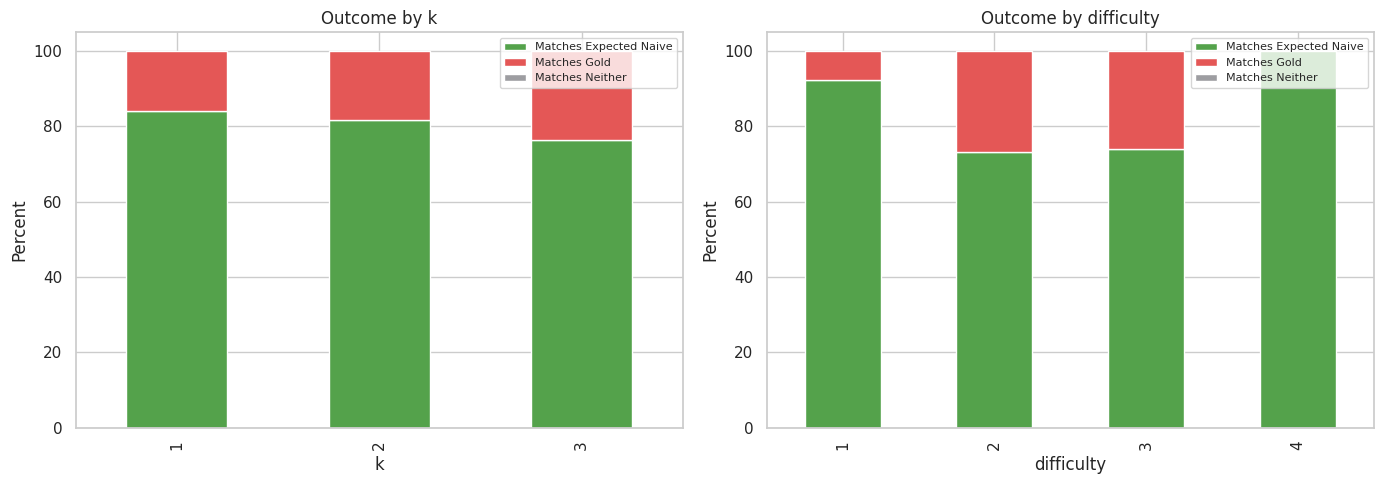

No Matches Neither cases were observed.
REPORT: No Matches Neither cases were observed, so no claim about which difficulty has more off-distribution outcomes can be made.


In [31]:
combined = combined.merge(
    df_leakage[["question_id", "k", "leakage_detected"]],
    on=["question_id", "k"],
)

def classify_outcome(row):
    if row["simulated_answer"] == row["expected_answer"]:
        return "Matches Expected Naive"
    if row["simulated_answer"] == row["gold_answer"]:
        return "Matches Gold"
    return "Matches Neither"

combined["outcome"] = combined.apply(classify_outcome, axis=1)
combined.to_csv("failure_classification.csv", index=False)

k_props = pd.crosstab(combined["k"], combined["outcome"], normalize="index") * 100
d_props = pd.crosstab(
    combined["difficulty"], combined["outcome"], normalize="index"
) * 100
order = ["Matches Expected Naive", "Matches Gold", "Matches Neither"]
colors = ["#54A24B", "#E45756", "#9D9DA1"]
k_props = k_props.reindex(columns=order, fill_value=0)
d_props = d_props.reindex(columns=order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
k_props.plot.bar(stacked=True, ax=axes[0], color=colors, title="Outcome by k")
d_props.plot.bar(stacked=True, ax=axes[1], color=colors, title="Outcome by difficulty")
for ax in axes:
    ax.set_ylabel("Percent")
    ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

neither = combined[combined["outcome"] == "Matches Neither"].copy()
if len(neither):
    neither["hypothesis"] = np.select(
        [
            neither["confidence"] < 0.55,
            neither["leakage_detected"],
        ],
        [
            "Model confusion: low confidence.",
            "Concept/prompt conflict: forbidden knowledge is still visible.",
        ],
        default="Ambiguous expected-answer mapping or concept extraction.",
    )
    display(neither[[
        "question_id", "k", "question_stem", "gold_answer",
        "expected_answer", "simulated_answer", "reasoning", "hypothesis"
    ]].head(2))
else:
    print("No Matches Neither cases were observed.")

neither_by_diff = combined.assign(
    is_neither=combined["outcome"].eq("Matches Neither")
).groupby("difficulty")["is_neither"].mean()
if len(neither):
    peak = neither_by_diff.idxmax()
    print(f"REPORT: Matches Neither is most common at difficulty {peak}.")
else:
    print(
        "REPORT: No Matches Neither cases were observed, so no claim about "
        "which difficulty has more off-distribution outcomes can be made."
    )


## 6. Comparative Summary


### 6.1 Pilot summary table


In [32]:
pilot_summary_data = (
    pilot_eval
    .merge(
        df_all_concepts.drop(columns=["raw_output"], errors="ignore"),
        on="question_id",
    )
)
pilot_summary_data["leakage"] = pilot_summary_data.apply(
    lambda r: leakage_evidence(
        r["reasoning"], missing_text(r, int(r["k"]))
    )[0],
    axis=1,
)
pilot_summary_data["match_gold"] = (
    pilot_summary_data["simulated_answer"] == pilot_summary_data["gold_answer"]
)
pilot_summary_data["match_expected"] = (
    pilot_summary_data["simulated_answer"] == pilot_summary_data["expected_answer"]
)
pilot_summary_data["off_distribution"] = ~(
    pilot_summary_data["match_gold"] | pilot_summary_data["match_expected"]
)

summary_table = (
    100 * pilot_summary_data.groupby(["strategy", "k"])[
        ["match_gold", "match_expected", "leakage", "off_distribution"]
    ].mean()
).rename(columns={
    "match_gold": "% Match Gold",
    "match_expected": "% Match Expected Naive",
    "leakage": "% Leakage",
    "off_distribution": "% Off-Distribution",
}).round(1)
assert len(summary_table) == 6, "Summary must contain A/B at k=1,2,3."
display(summary_table)


% Match Gold  % Match Expected Naive  % Leakage  \
strategy   k                                                    
Strategy A 1         100.0                    87.5       37.5   
           2         100.0                    87.5       50.0   
           3          87.5                    87.5       37.5   
Strategy B 1          37.5                    25.0       75.0   
           2          37.5                    25.0       87.5   
           3          12.5                    25.0       87.5   

              % Off-Distribution  
strategy   k                      
Strategy A 1                 0.0  
           2                 0.0  
           3                 0.0  
Strategy B 1                62.5  
           2                62.5  
           3                75.0

### 6.2 Confidence calibration


,mean_confidence,naive_accuracy,n
confidence_bin,,,
"(0.6, 0.8]",0.800,0.762,21
"(0.8, 1.0]",0.952,0.817,93


,mean_confidence,median_confidence,n
match_expected,,,
False,0.909,0.9,22
True,0.927,0.9,92


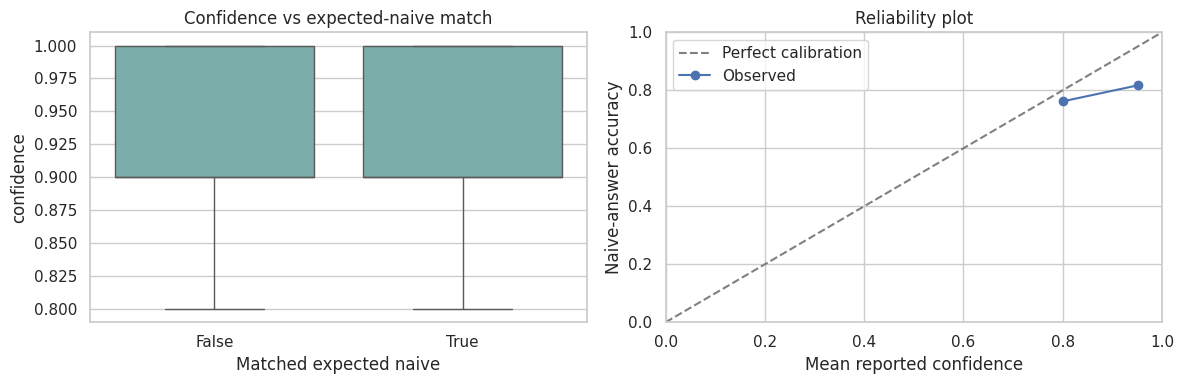

REPORT: Weighted absolute calibration gap = 0.117.
Signed confidence-minus-accuracy bias = 0.117; the model is overconfident on expected-naive prediction.
Mean confidence is 0.927 for expected-naive matches and 0.909 for non-matches. This directly tests whether reported confidence tracks success at simulating the naive learner.


In [33]:
combined["match_expected"] = (
    combined["simulated_answer"] == combined["expected_answer"]
)
combined["confidence_bin"] = pd.cut(
    combined["confidence"], bins=np.linspace(0, 1, 6), include_lowest=True
)
calibration_table = combined.groupby(
    "confidence_bin", observed=False
).agg(
    mean_confidence=("confidence", "mean"),
    naive_accuracy=("match_expected", "mean"),
    n=("match_expected", "size"),
).dropna()
display(calibration_table.round(3))
confidence_by_match = combined.groupby("match_expected").agg(
    mean_confidence=("confidence", "mean"),
    median_confidence=("confidence", "median"),
    n=("confidence", "size"),
)
display(confidence_by_match.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(
    data=combined, x="match_expected", y="confidence",
    ax=axes[0], color="#72B7B2"
)
axes[0].set(title="Confidence vs expected-naive match",
            xlabel="Matched expected naive")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
axes[1].plot(
    calibration_table["mean_confidence"],
    calibration_table["naive_accuracy"],
    "o-", label="Observed"
)
axes[1].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean reported confidence",
            ylabel="Naive-answer accuracy", title="Reliability plot")
axes[1].legend()
plt.tight_layout()
plt.show()

absolute_gap = np.average(
    np.abs(calibration_table["mean_confidence"] - calibration_table["naive_accuracy"]),
    weights=calibration_table["n"],
)
signed_bias = np.average(
    calibration_table["mean_confidence"] - calibration_table["naive_accuracy"],
    weights=calibration_table["n"],
)
print(f"REPORT: Weighted absolute calibration gap = {absolute_gap:.3f}.")
if signed_bias > 0.05:
    calibration_direction = "overconfident"
elif signed_bias < -0.05:
    calibration_direction = "underconfident"
else:
    calibration_direction = "approximately calibrated"
print(
    f"Signed confidence-minus-accuracy bias = {signed_bias:.3f}; "
    f"the model is {calibration_direction} on expected-naive prediction."
)
if combined["match_expected"].nunique() < 2:
    print(
        "All observations have the same match outcome, so confidence cannot "
        "be compared between successful and unsuccessful simulations."
    )
else:
    success_conf = confidence_by_match.loc[True, "mean_confidence"]
    failure_conf = confidence_by_match.loc[False, "mean_confidence"]
    print(
        f"Mean confidence is {success_conf:.3f} for expected-naive matches "
        f"and {failure_conf:.3f} for non-matches. This directly tests whether "
        "reported confidence tracks success at simulating the naive learner."
    )


### 6.3 Best configuration and runtime


In [34]:
best_config = (
    pilot_summary_data.groupby(["strategy", "k"])
    .agg(
        naive_match=("match_expected", "mean"),
        leakage=("leakage", "mean"),
        off_distribution=("off_distribution", "mean"),
    )
    .assign(score=lambda d: d["naive_match"] - 0.5*d["leakage"] - 0.25*d["off_distribution"])
    .sort_values("score", ascending=False)
)
display((100 * best_config).round(1))
best_strategy, best_k = best_config.index[0]
print(
    f"REPORT: Best pilot configuration = {best_strategy}, k={best_k}. "
    f"Scaled strategy = {CHOSEN_STRATEGY}. "
    + ("They agree." if best_strategy == CHOSEN_STRATEGY else
       "They differ; the pilot choice should be reconsidered.")
)

elapsed = time.perf_counter() - NOTEBOOK_START
print(f"Total notebook runtime after imports: {elapsed / 60:.2f} minutes")
print("Model usage:", dict(MODEL_USAGE))
print("Model failures/retries:", dict(MODEL_FAILURES))
print("Cache hits:", CACHE_HITS)
print("Generated files:")
for path in sorted(Path(".").glob("*.csv")):
    print(" -", path.name)


naive_match  leakage  off_distribution  score
strategy   k                                               
Strategy A 1         87.5     37.5               0.0   68.8
           3         87.5     37.5               0.0   68.8
           2         87.5     50.0               0.0   62.5
Strategy B 1         25.0     75.0              62.5  -28.1
           2         25.0     87.5              62.5  -34.4
           3         25.0     87.5              75.0  -37.5

REPORT: Best pilot configuration = Strategy A, k=1. Scaled strategy = Strategy A. They agree.
Total notebook runtime after imports: 51.15 minutes
Model usage: {'gemma-4-31b-it': 351, 'gemini-3.1-flash-lite': 754}
Model failures/retries: {'gemini-3.1-flash-lite': 1632}
Cache hits: 547
Generated files:
 - concepts_all.csv
 - concepts_pilot.csv
 - enriched_questions.csv
 - expected_naive_answers_pilot.csv
 - expected_naive_answers_scaled.csv
 - failure_classification.csv
 - leakage_analysis.csv
 - simulated_responses_pilot.csv
 - simulated_responses_scaled.csv


## Final notes

The pipeline is most sensitive to early concept extraction and to the validity
of expected-naive references. Real student responses would be a stronger target
than LLM-generated distractor mappings. The human-review cells record only
disagreements/corrections, so an empty dictionary means the displayed rows were
reviewed and accepted rather than skipped.
